# IMPORT THE LIBRARIES 

In [1]:
# Import pandas for data manipulation
import pandas as pd

# Import numpy for mathematical operations
import numpy as np

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Import seaborn for statistical visualization
import seaborn as sns

# Import dataset fetching function
from ucimlrepo import fetch_ucirepo

# Import preprocessing tools
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import missing-value handling
from sklearn.impute import SimpleImputer

# Import pipeline and column transformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Import machine learning models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Import evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Import cross-validation and tuning tools
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Import a simple baseline model
from sklearn.dummy import DummyRegressor

# Ignore unnecessary warnings in notebook output
import warnings
warnings.filterwarnings("ignore")

# LOAD THE DATASET 

In [2]:
# Fetch the Bike Sharing dataset from UCI
bike_data = fetch_ucirepo(id=275)

# Extract independent variables
X = bike_data.data.features

# Extract the target variable
y = bike_data.data.targets

# Combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

# Display the first five records
df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


# Explore the Dataset 

In [4]:
print("Dataset Shape:", df.shape)                         # Display the number of rows and columns

Dataset Shape: (17379, 14)


In [6]:
df.columns.tolist()                                       # Display all column names

['dteday',
 'season',
 'yr',
 'mnth',
 'hr',
 'holiday',
 'weekday',
 'workingday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'cnt']

In [7]:
df.info()                                   # Display information about the dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  object 
 1   season      17379 non-null  int64  
 2   yr          17379 non-null  int64  
 3   mnth        17379 non-null  int64  
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weekday     17379 non-null  int64  
 7   workingday  17379 non-null  int64  
 8   weathersit  17379 non-null  int64  
 9   temp        17379 non-null  float64
 10  atemp       17379 non-null  float64
 11  hum         17379 non-null  float64
 12  windspeed   17379 non-null  float64
 13  cnt         17379 non-null  int64  
dtypes: float64(4), int64(9), object(1)
memory usage: 1.9+ MB


In [8]:
df.describe()                                       # Display statistical summary

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,189.463088
std,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,181.387599
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,40.000000
50%,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,142.000000
75%,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,281.000000
max,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,977.000000


In [10]:
print(df.isnull().sum())                                   # Check missing values in every column

dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
cnt           0
dtype: int64


In [12]:
print("Duplicate Records:", df.duplicated().sum())                      # Check duplicate records

Duplicate Records: 0


In [14]:
print(df.dtypes)                                       # Check data types

dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
cnt             int64
dtype: object


# VISUALIZE THE TAGRGET VARIABLE 

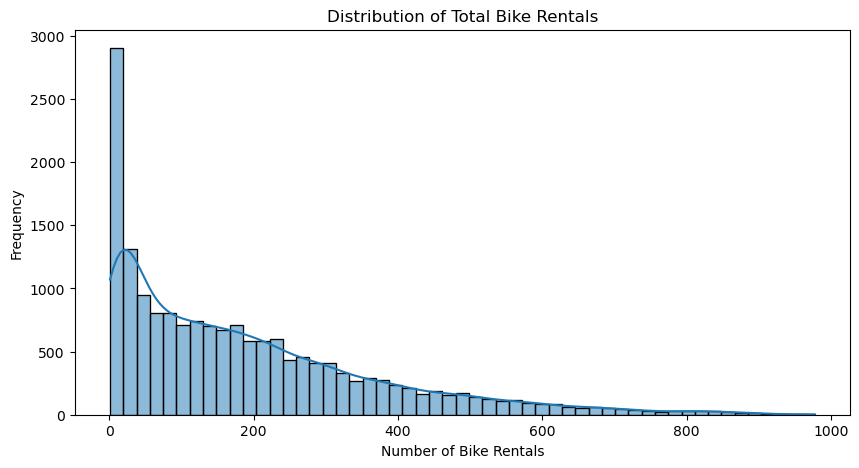

In [15]:
# Plot the distribution of total bike rentals

plt.figure(figsize=(10, 5))

sns.histplot(df["cnt"], kde=True)

plt.title("Distribution of Total Bike Rentals")
plt.xlabel("Number of Bike Rentals")
plt.ylabel("Frequency")


# FEATURE SELECTION & DATA LEAKAGE PREVENTION 

In [16]:
# Remove columns that should not be used for prediction
columns_to_remove = [
    "instant",
    "casual",
    "registered"
]

# Keep only columns that actually exist in the dataset
columns_to_remove = [
    col for col in columns_to_remove if col in df.columns
]

# Remove the unwanted columns
df = df.drop(columns=columns_to_remove)

# Display the remaining columns
print(df.columns.tolist())

['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']


# FEATURE ENGINEERING 

In [17]:
# Convert the date column into datetime format
df["dteday"] = pd.to_datetime(df["dteday"])

# Extract the day from the date
df["day"] = df["dteday"].dt.day

# Extract the month from the date
df["month"] = df["dteday"].dt.month

# Extract the year from the date
df["year"] = df["dteday"].dt.year

# Create cyclical hour features
df["hour_sin"] = np.sin(2 * np.pi * df["hr"] / 24)

df["hour_cos"] = np.cos(2 * np.pi * df["hr"] / 24)

# Create cyclical month features
df["month_sin"] = np.sin(2 * np.pi * df["mnth"] / 12)

df["month_cos"] = np.cos(2 * np.pi * df["mnth"] / 12)

# Display the newly created features
df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,...,hum,windspeed,cnt,day,month,year,hour_sin,hour_cos,month_sin,month_cos
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,...,0.81,0.0,16,1,1,2011,0.000000,1.000000,0.5,0.866025
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,...,0.80,0.0,40,1,1,2011,0.258819,0.965926,0.5,0.866025
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,...,0.80,0.0,32,1,1,2011,0.500000,0.866025,0.5,0.866025
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,...,0.75,0.0,13,1,1,2011,0.707107,0.707107,0.5,0.866025
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,...,0.75,0.0,1,1,1,2011,0.866025,0.500000,0.5,0.866025


# PREPARE TRAINING & TESTING DATASET

In [18]:
# Sort the dataset by date and hour
df = df.sort_values(
    by=["dteday", "hr"]
).reset_index(drop=True)

# Remove the original date column after extracting useful features
df = df.drop(columns=["dteday"])

# Separate independent variables
X = df.drop(columns=["cnt"])

# Select the target variable
y = df["cnt"]

# Calculate the position for an 80:20 chronological split
split_index = int(len(df) * 0.80)

# Select the first 80% for training
X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

# Select the remaining 20% for testing
X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

# Display dataset sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (13903, 19)
Testing data: (3476, 19)


# BUILDING PREPROCESSING PIPELINE

In [19]:
# Identify categorical columns
categorical_features = [
    "season",
    "holiday",
    "weekday",
    "workingday",
    "weathersit"
]

# Identify numerical columns
numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Create numerical preprocessing pipeline
num_pipeline = Pipeline([
    # Replace missing numerical values with the median
    ("imputer", SimpleImputer(strategy="median")),

    # Standardize numerical values
    ("scaler", StandardScaler())
])

# Create categorical preprocessing pipeline
cat_pipeline = Pipeline([
    # Replace missing categorical values with the most frequent value
    ("imputer", SimpleImputer(strategy="most_frequent")),

    # Convert categories into numerical columns
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", num_pipeline, numerical_features),

    ("cat", cat_pipeline, categorical_features)
])

In [20]:
preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [21]:
cat_pipeline

,steps,"[('imputer', ...), ('encoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [22]:
num_pipeline

,steps,"[('imputer', ...), ('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


# TRAIN MACHINE LEARNING MODELS 

In [23]:
# Create a pipeline for Linear Regression
linear_model = Pipeline([
    # Apply preprocessing
    ("preprocessing", preprocessor),

    # Train the Linear Regression algorithm
    ("model", LinearRegression())
])

# Train the model using training data
linear_model.fit(X_train, y_train)

# Predict bike rental demand
linear_predictions = linear_model.predict(X_test)

In [24]:
linear_model

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [25]:
linear_predictions

array([372.50482653, 388.04861185, 407.62467767, ..., 188.71472384,
       167.72452362, 142.18463969], shape=(3476,))

# DECISION TREE REGRESSOR 

In [27]:
# Create a Decision Tree pipeline
tree_model = Pipeline([
    # Apply preprocessing
    ("preprocessing", preprocessor),

    # Create the Decision Tree model
    ("model", DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ))
])

# Train the Decision Tree
tree_model.fit(X_train, y_train)

# Generate predictions
tree_predictions = tree_model.predict(X_test)

In [28]:
tree_model

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [29]:
tree_predictions

array([250.78395062, 250.78395062, 250.78395062, ..., 114.5       ,
        95.45454545,  47.52631579], shape=(3476,))

# RANDOM FOREST REGRESSOR 

In [31]:
# Create the Random Forest pipeline
forest_model = Pipeline([
    # Apply preprocessing
    ("preprocessing", preprocessor),

    # Create the Random Forest model
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the Random Forest model
forest_model.fit(X_train, y_train)

# Predict bike rental demand
forest_predictions = forest_model.predict(X_test)

In [32]:
forest_model

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [33]:
forest_predictions

array([270.311046  , 269.3639153 , 266.9370744 , ..., 115.98      ,
        93.40177778,  56.52639238], shape=(3476,))

# EVALUATE MODEL PERFORMANCE 

In [35]:
# Create a function to evaluate regression models
def evaluate_model(y_actual, y_predicted):

    # Calculate Mean Absolute Error
    mae = mean_absolute_error(
        y_actual,
        y_predicted
    )

    # Calculate Mean Squared Error
    mse = mean_squared_error(
        y_actual,
        y_predicted
    )

    # Calculate Root Mean Squared Error
    rmse = np.sqrt(mse)

    # Calculate R2 score
    r2 = r2_score(
        y_actual,
        y_predicted
    )

    # Return all evaluation metrics
    return mae, mse, rmse, r2

In [40]:
evaluate_model

<function __main__.evaluate_model(y_actual, y_predicted)>

# COMPARE MODEL PERFORMANCE 

In [42]:
# Store model predictions
predictions = {
    "Linear Regression": linear_predictions,
    "Decision Tree": tree_predictions,
    "Random Forest": forest_predictions
}

# Create an empty list for evaluation results
results = []

# Evaluate every model
for model_name, prediction in predictions.items():

    # Calculate evaluation metrics
    mae, mse, rmse, r2 = evaluate_model(
        y_test,
        prediction
    )

    # Store the results
    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Sort models by RMSE
results_df = results_df.sort_values(
    by="RMSE"
)

# Display the comparison
results_df

,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,50.880061,5920.879417,76.947251,0.878205
1,Decision Tree,58.062340,7805.926562,88.351155,0.839429
0,Linear Regression,122.090996,27112.574115,164.658963,0.442284


# VISUALIZE ACTUAL VS PREDICTED VALUES 

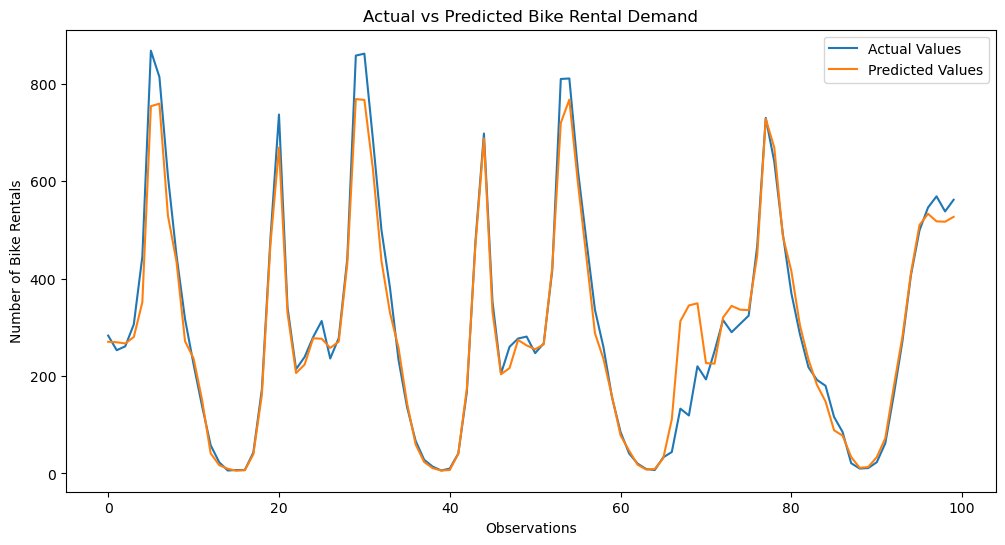

In [43]:
# Plot actual and predicted rental counts
plt.figure(figsize=(12, 6))

# Plot actual values
plt.plot(
    y_test.iloc[:100].values,
    label="Actual Values"
)

# Plot Random Forest predictions
plt.plot(
    forest_predictions[:100],
    label="Predicted Values"
)

# Add chart title and labels
plt.title("Actual vs Predicted Bike Rental Demand")

plt.xlabel("Observations")

plt.ylabel("Number of Bike Rentals")

plt.legend()

plt.show()

# CROSS VALIDAION 

In [45]:
# Create time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Create a pipeline for cross-validation
cv_model = Pipeline([
    ("preprocessing", preprocessor),

    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Perform cross-validation using negative RMSE
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Convert negative scores into positive RMSE
cv_rmse = -cv_scores

# Display individual fold results
print("Cross-validation RMSE:", cv_rmse)

# Display average RMSE
print("Average RMSE:", cv_rmse.mean())

# Display variation across folds
print("RMSE Standard Deviation:", cv_rmse.std())

Cross-validation RMSE: [ 91.91373094  54.0932715   67.68694349 110.92516864  78.68262228]
Average RMSE: 80.6603473683622
RMSE Standard Deviation: 19.59912331321174


# HYPERPARAMETER TUNING 

In [46]:
# Create the Random Forest pipeline
tuning_pipeline = Pipeline([
    ("preprocessing", preprocessor),

    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

# Define different parameter combinations
param_grid = {
    "model__n_estimators": [100, 200],

    "model__max_depth": [10, 15, 20],

    "model__min_samples_split": [2, 5],

    "model__min_samples_leaf": [1, 2]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=tuning_pipeline,

    param_grid=param_grid,

    cv=TimeSeriesSplit(n_splits=3),

    scoring="neg_root_mean_squared_error",

    n_jobs=-1,

    verbose=1
)

# Train and tune the model
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best Parameters:")
print(grid_search.best_params_)

# Display the best cross-validation RMSE
print("Best CV RMSE:")
print(-grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV RMSE:
81.04058496812169


# EVALUATE THE TUNED MODEL 

In [47]:
# Retrieve the best tuned model
best_model = grid_search.best_estimator_

# Generate predictions on unseen test data
tuned_predictions = best_model.predict(X_test)

# Evaluate the tuned model
tuned_mae, tuned_mse, tuned_rmse, tuned_r2 = evaluate_model(
    y_test,
    tuned_predictions
)

# Display the final evaluation metrics
print("Tuned Model Performance")

print("MAE:", tuned_mae)

print("MSE:", tuned_mse)

print("RMSE:", tuned_rmse)

print("R2 Score:", tuned_r2)

Tuned Model Performance
MAE: 50.53643842129292
MSE: 5866.6509848886
RMSE: 76.59406625116988
R2 Score: 0.8793206743038633


# FEATURE IMPORTANCE 

In [48]:
# Extract the trained Random Forest model
rf_model = best_model.named_steps["model"]

# Extract the fitted preprocessing component
fitted_preprocessor = best_model.named_steps["preprocessing"]

# Get the names of transformed features
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance values
importance_values = rf_model.feature_importances_

# Create a DataFrame containing feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort features from highest to lowest importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
importance_df.head(15)

,Feature,Importance
2,num__hr,0.382007
10,num__hour_sin,0.155628
4,num__atemp,0.088470
3,num__temp,0.074478
11,num__hour_cos,0.065125
9,num__year,0.036684
0,num__yr,0.032352
28,cat__workingday_1,0.030603
27,cat__workingday_0,0.030306
5,num__hum,0.024030


# VISUALIZE THE FEATURE 

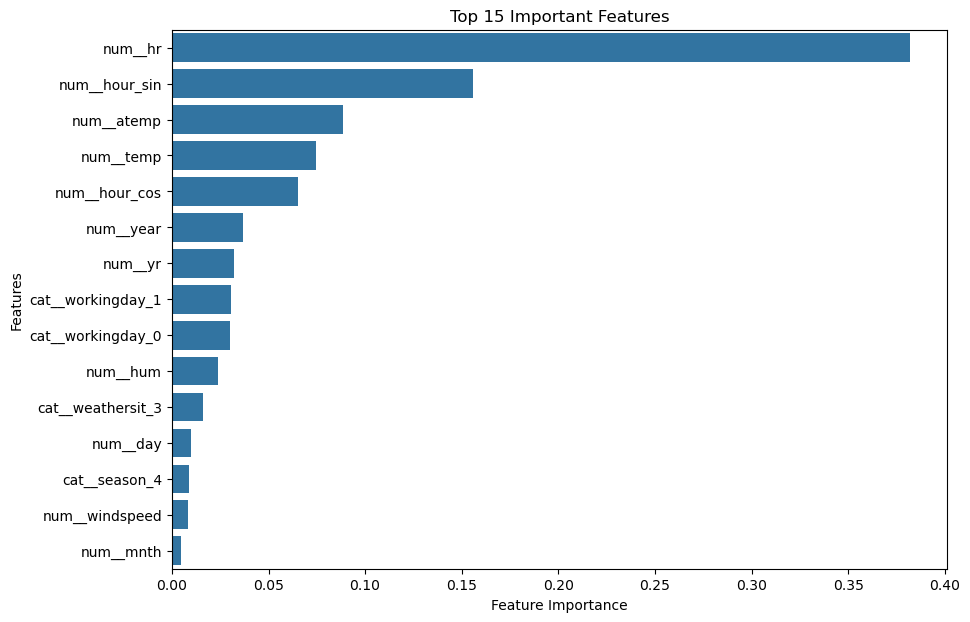

In [49]:
# Select the top 15 important features
top_features = importance_df.head(15)

# Create a horizontal bar chart
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")

plt.xlabel("Feature Importance")

plt.ylabel("Features")

plt.show()

# CREATE A BASELINE MODEL 

In [50]:
# Create a baseline model that always predicts the training mean
baseline_model = DummyRegressor(strategy="mean")

# Train the baseline model
baseline_model.fit(X_train, y_train)

# Generate baseline predictions
baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline performance
baseline_results = evaluate_model(
    y_test,
    baseline_predictions
)

# Display baseline RMSE
print("Baseline RMSE:", baseline_results[2])

Baseline RMSE: 232.60837481037086


# COMPARE ALL THE BASELINE MODELS 

In [51]:
# Create a dictionary containing all model predictions
all_predictions = {
    "Baseline": baseline_predictions,
    "Linear Regression": linear_predictions,
    "Decision Tree": tree_predictions,
    "Random Forest": forest_predictions,
    "Tuned Random Forest": tuned_predictions
}

# Create an empty list to store results
comparison_results = []

# Evaluate each model
for model_name, predictions in all_predictions.items():

    # Calculate MAE, MSE, RMSE and R2
    mae, mse, rmse, r2 = evaluate_model(
        y_test,
        predictions
    )

    # Store evaluation results
    comparison_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Convert results into a DataFrame
comparison_df = pd.DataFrame(comparison_results)

# Display models with the lowest RMSE first
comparison_df = comparison_df.sort_values(
    by="RMSE"
)

# Display the comparison table
comparison_df

,Model,MAE,MSE,RMSE,R2 Score
4,Tuned Random Forest,50.536438,5866.650985,76.594066,0.879321
3,Random Forest,50.880061,5920.879417,76.947251,0.878205
2,Decision Tree,58.062340,7805.926562,88.351155,0.839429
1,Linear Regression,122.090996,27112.574115,164.658963,0.442284
0,Baseline,174.984601,54106.656032,232.608375,-0.112995


# VISUALIZE MODEL PERFORMANCE 

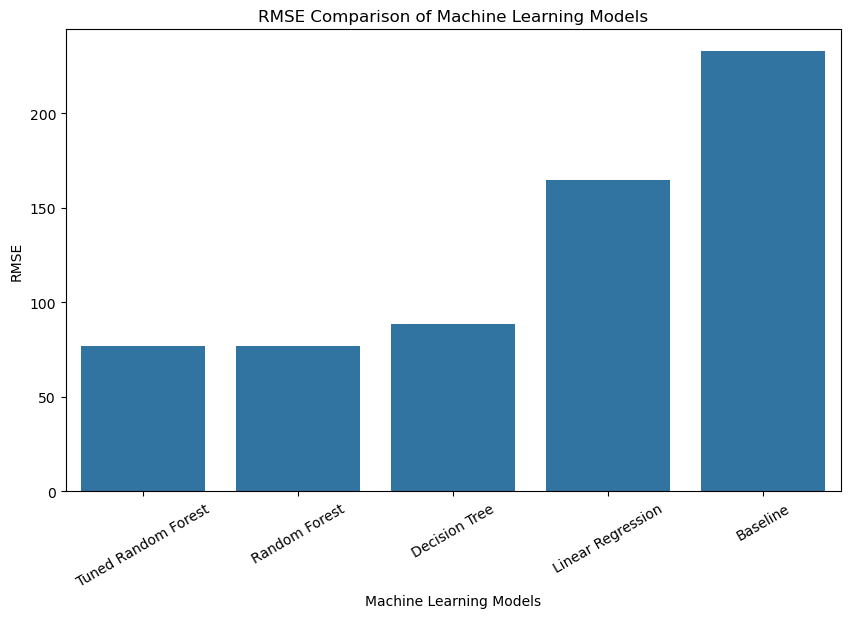

In [52]:
# Create a figure
plt.figure(figsize=(10, 6))

# Create a bar chart of RMSE values
sns.barplot(
    data=comparison_df,
    x="Model",
    y="RMSE"
)

# Add chart title
plt.title("RMSE Comparison of Machine Learning Models")

# Add axis labels
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")

# Rotate model names for readability
plt.xticks(rotation=30)

# Display chart
plt.show()

# ANALYZE PREDICTION ERROR 

In [53]:
# Calculate residuals
residuals = y_test - tuned_predictions

# Create a residual DataFrame
residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": tuned_predictions,
    "Residual": residuals.values
})

# Display the first five residual records
residual_df.head()

,Actual,Predicted,Residual
0,283,277.846018,5.153982
1,253,274.936848,-21.936848
2,261,277.704003,-16.704003
3,306,279.642587,26.357413
4,445,347.076307,97.923693


# RESIDUAL DISTRIBUTION 

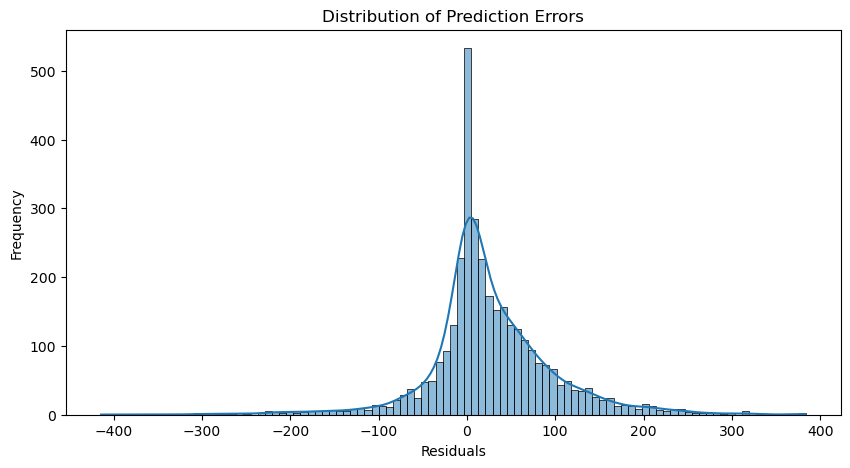

In [54]:
# Create residual distribution plot
plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Distribution of Prediction Errors")

plt.xlabel("Residuals")

plt.ylabel("Frequency")

plt.show()

# RESIDUAL VS PREDICTED VALUES 

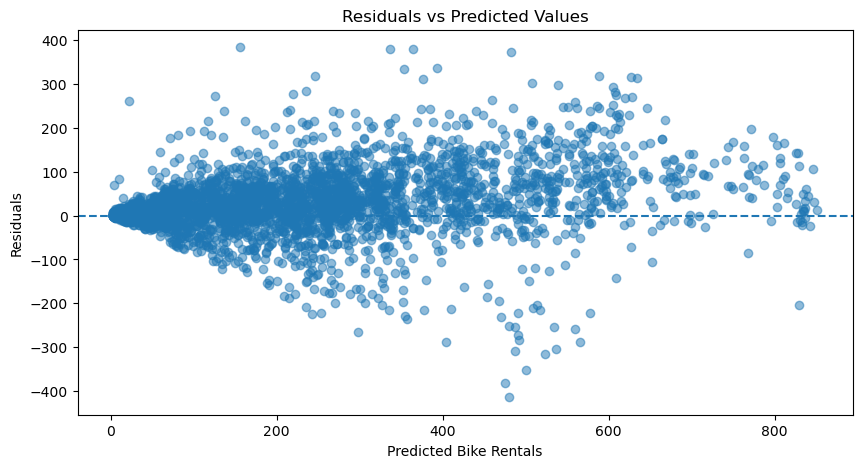

In [55]:
# Create residual scatter plot
plt.figure(figsize=(10, 5))

plt.scatter(
    tuned_predictions,
    residuals,
    alpha=0.5
)

# Add horizontal reference line at zero
plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residuals vs Predicted Values")

plt.xlabel("Predicted Bike Rentals")

plt.ylabel("Residuals")

plt.show()

# ANALYZE ACTUAL VS PREDICTED VALUES 

In [56]:
# Create a comparison DataFrame
prediction_comparison = pd.DataFrame({
    "Actual Rentals": y_test.values,
    "Predicted Rentals": tuned_predictions
})

# Display the first ten predictions
prediction_comparison.head(10)

,Actual Rentals,Predicted Rentals
0,283,277.846018
1,253,274.936848
2,261,277.704003
3,306,279.642587
4,445,347.076307
5,868,741.807500
6,814,747.625500
7,610,530.615000
8,448,442.723114
9,317,275.441373


# SCATTER PLOT 

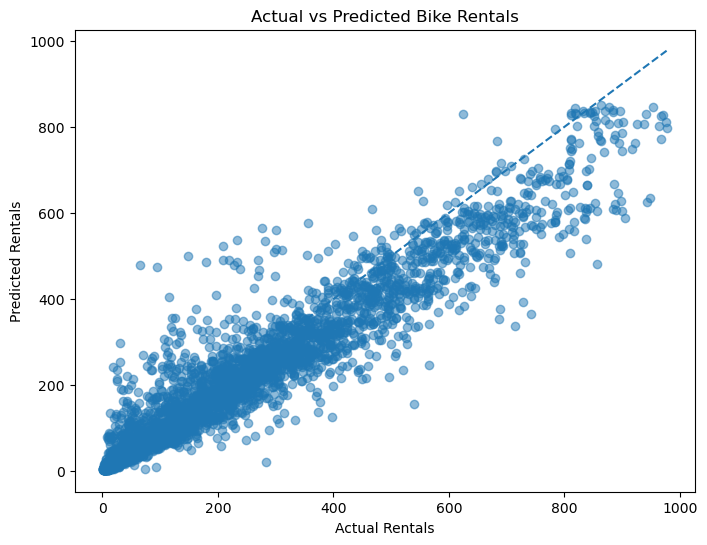

In [57]:
# Create scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    tuned_predictions,
    alpha=0.5
)

# Add a reference line
min_value = min(y_test.min(), tuned_predictions.min())

max_value = max(y_test.max(), tuned_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Bike Rentals")

plt.xlabel("Actual Rentals")

plt.ylabel("Predicted Rentals")

plt.show()

# ANALYZE FAETURE IMPORTANCE 

In [58]:
# Display the top 10 important features
importance_df.head(10)

,Feature,Importance
2,num__hr,0.382007
10,num__hour_sin,0.155628
4,num__atemp,0.088470
3,num__temp,0.074478
11,num__hour_cos,0.065125
9,num__year,0.036684
0,num__yr,0.032352
28,cat__workingday_1,0.030603
27,cat__workingday_0,0.030306
5,num__hum,0.024030


# MODEL REFINEMENT 

In [59]:
# Create a new dataset from the original cleaned dataset
df_improved = df.copy()

# Create a time-of-day feature
# This assumes the original hour column was preserved separately.